# Work Session 04

## Overfitting, data leakage and model generalization

# Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Done**

# Part A : Data Inspection and Potential Leakage

## A.1 - Load and inspect the data

### Loading

In [2]:
df = pd.read_csv("hybrid_student_performance_1200.csv")

### Data inspecting

In [3]:
df.head()

,student_id,timestamp,year_class,program_stream,age,gender,cgpa_category,academic_satisfaction,study_hours_daily,daily_productivity,...,projects_internships,programming_foundation,events_participation,assignments_on_time,attendance_percentage,strongest_asset,internal_barrier,external_resources,external_pressure,performance_risk_level
0,STU0001,3/29/2026 20:54:43,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,Less than 1 hour,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing",Occasionally participate in events,Often,Above 85%,"Technical/Hard Skills (Coding, Math, Logic)",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),No Impact (Fully supportive environment),Moderate Risk
1,STU0002,3/29/2026 21:20:15,Second Year (SY),BCA,20,Male,8.5 – 9.4,Unsatisfied,1–2 hours,1.0,...,"Yes, actively working on projects/internship","Limited knowledge, theoretical only","Rarely participate, mostly observe",Often,76% – 85%,"Creative/Design Skills (Innovation, UI/UX, Con...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),Moderate Impact (Occasional disruption),Moderate Risk
2,STU0003,3/29/2026 21:21:35,Second Year (SY),BCA,19,Male,5.0 – 6.9,Neutral,1–2 hours,2.0,...,"Yes, actively working on projects/internship","Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Less than 50%,"Technical/Hard Skills (Coding, Math, Logic)",Difficulty with Focus / Concentration,Rarely (Passive),High Impact (Frequent disruption),High Risk
3,STU0004,3/29/2026 21:27:44,Second Year (SY),BCA,19,Female,8.5 – 9.4,Satisfied,1–2 hours,3.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing","Rarely participate, mostly observe",Often,Above 85%,"Management/Execution (Planning, Organizing, Di...",Procrastination / Low Motivation,Occasionally (When needed),High Impact (Frequent disruption),Low Risk
4,STU0005,3/29/2026 22:05:14,Second Year (SY),BCA,20,Female,8.5 – 9.4,Neutral,1–2 hours,2.0,...,Planning to start a project/internship soon,"Basic knowledge, learning while practicing",Occasionally participate in events,Often,76% – 85%,"Management/Execution (Planning, Organizing, Di...",Lack of Consistency or Determination (Difficul...,Occasionally (When needed),High Impact (Frequent disruption),High Risk


In [4]:
print(df.shape)

(1200, 36)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              1200 non-null   str    
 1   timestamp               1200 non-null   str    
 2   year_class              1200 non-null   str    
 3   program_stream          1200 non-null   str    
 4   age                     1200 non-null   int64  
 5   gender                  1200 non-null   str    
 6   cgpa_category           1200 non-null   str    
 7   academic_satisfaction   1200 non-null   str    
 8   study_hours_daily       1200 non-null   str    
 9   daily_productivity      1166 non-null   float64
 10  revision_frequency      1166 non-null   str    
 11  focus_duration          1157 non-null   str    
 12  screen_time_non_study   1168 non-null   str    
 13  main_distractor         1200 non-null   str    
 14  study_consistency       1200 non-null   str    
 15

In [6]:
df.describe()

,age,daily_productivity,energy_level,stress_level,routine_rating
count,1200.000000,1166.000000,1172.000000,1165.000000,1159.000000
mean,20.807500,2.686964,3.227816,3.151931,2.105263
std,2.186953,1.178761,1.145359,1.189194,0.788057
min,17.000000,1.000000,1.000000,1.000000,1.000000
25%,19.000000,2.000000,2.000000,2.000000,1.000000
50%,21.000000,3.000000,3.000000,3.000000,2.000000
75%,22.000000,3.000000,4.000000,4.000000,3.000000
max,26.000000,5.000000,5.000000,5.000000,3.000000


### Categorical columns

In [7]:
df['external_pressure'].unique().tolist()

['No Impact (Fully supportive environment)',
 'Moderate Impact (Occasional disruption)',
 'High Impact (Frequent disruption)',
 'Low Impact (Rarely affects study)',
 nan]

- I did same for ceveral cassification Columns and all have several unique data. 
- its good.

### Missing values

In [8]:
col_missing_values = df.isnull().sum().rename("missing_number").to_frame()

In [9]:
col_missing_percent = df.isna().mean().mul(100).round(1).rename("missing_percent %")


In [10]:
print(pd.concat([col_missing_percent, col_missing_values], axis=1)[col_missing_percent > 0])

                        missing_percent %  missing_number
daily_productivity                    2.8              34
revision_frequency                    2.8              34
focus_duration                        3.6              43
screen_time_non_study                 2.7              32
energy_level                          2.3              28
stress_level                          2.9              35
routine_rating                        3.4              41
sleep_hours                           4.6              55
online_courses                        3.0              36
programming_foundation                3.4              41
events_participation                  4.8              58
external_resources                    3.8              45
external_pressure                     2.4              29


- Those are columns with missing values, the number & Percent of missing values in each column. 

**Question:** Examine dimensions, data types, descriptive statistics and missing values.

**Answer:** 1200 rows x 36 columns, mostly text (categorical) columns. 13 columns have 2.3% to 4.8% missing values (511 cells, 35.6% of rows have at least one).

## A.2 - Duplicates

In [11]:
print(df.duplicated().sum())  

0


- So there is no duplicates.

**Question:** How many duplicates are there (with and without `student_id`, ignoring `timestamp`)?

**Answer:** 0 in all cases. Part B.2 introduces duplicates in a controlled way.

## A.3 - Build target/features + correlation

### Columns

In [12]:
df.columns

Index(['student_id', 'timestamp', 'year_class', 'program_stream', 'age',
       'gender', 'cgpa_category', 'academic_satisfaction', 'study_hours_daily',
       'daily_productivity', 'revision_frequency', 'focus_duration',
       'screen_time_non_study', 'main_distractor', 'study_consistency',
       'tasks_on_time', 'preparation_status', 'career_goal_clarity',
       'skills_developing', 'energy_level', 'stress_level', 'routine_rating',
       'sleepy_during_study', 'sleep_hours', 'career_interest',
       'online_courses', 'projects_internships', 'programming_foundation',
       'events_participation', 'assignments_on_time', 'attendance_percentage',
       'strongest_asset', 'internal_barrier', 'external_resources',
       'external_pressure', 'performance_risk_level'],
      dtype='str')

### A.3.1 - Target : cgpa_category

In [13]:
df['cgpa_category'].unique()

<ArrowStringArray>
['8.5 – 9.4', '5.0 – 6.9', '9.5 – 10.0', '7.0 – 8.4']
Length: 4, dtype: str

- Lets turn **cgpa_category** to **final_cgpa**

In [14]:
df["final_cgpa"] = df["cgpa_category"].map({
    "5.0 – 6.9": 5.95,
    "7.0 – 8.4": 7.70,
    "8.5 – 9.4": 8.95,
    "9.5 – 10.0": 9.75
})

print(df[["cgpa_category", "final_cgpa"]].head())

  cgpa_category  final_cgpa
0     8.5 – 9.4        8.95
1     8.5 – 9.4        8.95
2     5.0 – 6.9        5.95
3     8.5 – 9.4        8.95
4     8.5 – 9.4        8.95


**Done**

### A.3.2 - Features

#### Type 1 : ranges to midpoint

- Now lest do same for ranges :  **ranges** -->  **midpoint**


In [15]:
df['study_hours_daily'].unique()

<ArrowStringArray>
['Less than 1 hour', '1–2 hours', 'More than 2 hours']
Length: 3, dtype: str

In [16]:
df["study_hours"] = df["study_hours_daily"].map({
    "Less than 1 hour": 0.5,
    "1–2 hours": 1.5,
    "More than 2 hours": 2.5
})

In [17]:
df[["study_hours", "study_hours_daily"]].head()

,study_hours,study_hours_daily
0,0.5,Less than 1 hour
1,1.5,1–2 hours
2,1.5,1–2 hours
3,1.5,1–2 hours
4,1.5,1–2 hours


In [18]:
df['sleep_hours'].unique()

<ArrowStringArray>
['6–7 hours', '4–5 hours', 'More than 8 hours', nan]
Length: 4, dtype: str

In [19]:
df["sleep_hours_nb"] = df["sleep_hours"].map({
    "4–5 hours": 4.5,
    "6–7 hours": 6.5,
    "More than 8 hours": 8.5
})

In [20]:
df[["sleep_hours_nb", "sleep_hours"]].head()

,sleep_hours_nb,sleep_hours
0,6.5,6–7 hours
1,6.5,6–7 hours
2,6.5,6–7 hours
3,6.5,6–7 hours
4,4.5,4–5 hours


In [21]:
df['attendance_percentage'].unique()

<ArrowStringArray>
['Above 85%', '76% – 85%', 'Less than 50%', '50% – 65%', '66% – 75%']
Length: 5, dtype: str

In [22]:
df["attendance_rate"] = df["attendance_percentage"].map({
    "Less than 50%": 40,
    "50% – 65%": 57.5,
    "66% – 75%": 70.5,
    "76% – 85%": 80.5,
    "Above 85%": 92.5
})

In [23]:
df[["attendance_rate", "attendance_percentage"]].head()

,attendance_rate,attendance_percentage
0,92.5,Above 85%
1,80.5,76% – 85%
2,40.0,Less than 50%
3,92.5,Above 85%
4,80.5,76% – 85%


#### Type 2 : order

In [24]:
df['study_consistency'].unique()

<ArrowStringArray>
['Rarely', 'Sometimes', 'Mostly consistent']
Length: 3, dtype: str

In [25]:
df["study_consistency_rate"] = df["study_consistency"].map(
    {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2})

In [26]:
df[["study_consistency_rate", "study_consistency"]].head()

,study_consistency_rate,study_consistency
0,0,Rarely
1,1,Sometimes
2,2,Mostly consistent
3,1,Sometimes
4,1,Sometimes


In [27]:
df['tasks_on_time'].unique()

<ArrowStringArray>
['Sometimes', 'Often', 'Always', 'Rarely']
Length: 4, dtype: str

In [28]:
df['assignments_on_time'].unique()

<ArrowStringArray>
['Often', 'Sometimes', 'Always', 'Rarely']
Length: 4, dtype: str

In [29]:
freq = {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3}
df["tasks_on_time_rate"] = df["tasks_on_time"].map(freq)
df["assignments_on_time_rate"] = df["assignments_on_time"].map(freq)

In [30]:
df[["tasks_on_time_rate", "tasks_on_time", "assignments_on_time_rate", "assignments_on_time"]].head()

,tasks_on_time_rate,tasks_on_time,assignments_on_time_rate,assignments_on_time
0,1,Sometimes,2,Often
1,1,Sometimes,2,Often
2,2,Often,2,Often
3,2,Often,2,Often
4,1,Sometimes,2,Often


In [31]:
df['revision_frequency'].unique()

<ArrowStringArray>
['Never', 'Rarely', 'Few times a week', 'Daily', nan]
Length: 5, dtype: str

In [32]:
df["revision_frequency_rate"] = df["revision_frequency"].map(
    {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3})

In [33]:
df[["revision_frequency_rate", "revision_frequency"]].head()

,revision_frequency_rate,revision_frequency
0,0.0,Never
1,1.0,Rarely
2,2.0,Few times a week
3,1.0,Rarely
4,1.0,Rarely


In [34]:
df['career_goal_clarity'].unique()

<ArrowStringArray>
['Somewhat clear', 'Very clear', 'Not clear']
Length: 3, dtype: str

In [35]:
df["career_goal_clarity_rate"] = df["career_goal_clarity"].map(
    {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2})

In [36]:
df[["career_goal_clarity_rate", "career_goal_clarity"]].head()

,career_goal_clarity_rate,career_goal_clarity
0,1,Somewhat clear
1,1,Somewhat clear
2,2,Very clear
3,1,Somewhat clear
4,1,Somewhat clear


#### Type 3 : the day

In [37]:
df['timestamp'].head(3)

0    3/29/2026 20:54:43
1    3/29/2026 21:20:15
2    3/29/2026 21:21:35
Name: timestamp, dtype: str

In [38]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

In [39]:
df['timestamp'].head(3)

0   2026-03-29 20:54:43
1   2026-03-29 21:20:15
2   2026-03-29 21:21:35
Name: timestamp, dtype: datetime64[us]

In [40]:

df["submission_day"] = (
    df["timestamp"] - df["timestamp"].min()
).dt.days

In [41]:
df[["submission_day", "timestamp"]].head(3)

,submission_day,timestamp
0,14,2026-03-29 20:54:43
1,14,2026-03-29 21:20:15
2,14,2026-03-29 21:21:35


**Done**

### A.3.3 - Check the new columns

- Now Lest Check our New data  :

In [42]:
df[[
    "final_cgpa", "cgpa_category",
    "study_hours", "study_hours_daily",
    "sleep_hours_nb", "sleep_hours",
    "attendance_rate", "attendance_percentage",
    "study_consistency_rate", "study_consistency",
    "tasks_on_time_rate", "tasks_on_time",
    "assignments_on_time_rate", "assignments_on_time",
    "revision_frequency_rate", "revision_frequency",
    "career_goal_clarity_rate", "career_goal_clarity",
    "submission_day", "timestamp"
]].head()

,final_cgpa,cgpa_category,study_hours,study_hours_daily,sleep_hours_nb,sleep_hours,attendance_rate,attendance_percentage,study_consistency_rate,study_consistency,tasks_on_time_rate,tasks_on_time,assignments_on_time_rate,assignments_on_time,revision_frequency_rate,revision_frequency,career_goal_clarity_rate,career_goal_clarity,submission_day,timestamp
0,8.95,8.5 – 9.4,0.5,Less than 1 hour,6.5,6–7 hours,92.5,Above 85%,0,Rarely,1,Sometimes,2,Often,0.0,Never,1,Somewhat clear,14,2026-03-29 20:54:43
1,8.95,8.5 – 9.4,1.5,1–2 hours,6.5,6–7 hours,80.5,76% – 85%,1,Sometimes,1,Sometimes,2,Often,1.0,Rarely,1,Somewhat clear,14,2026-03-29 21:20:15
2,5.95,5.0 – 6.9,1.5,1–2 hours,6.5,6–7 hours,40.0,Less than 50%,2,Mostly consistent,2,Often,2,Often,2.0,Few times a week,2,Very clear,14,2026-03-29 21:21:35
3,8.95,8.5 – 9.4,1.5,1–2 hours,6.5,6–7 hours,92.5,Above 85%,1,Sometimes,2,Often,2,Often,1.0,Rarely,1,Somewhat clear,14,2026-03-29 21:27:44
4,8.95,8.5 – 9.4,1.5,1–2 hours,4.5,4–5 hours,80.5,76% – 85%,1,Sometimes,1,Sometimes,2,Often,1.0,Rarely,1,Somewhat clear,14,2026-03-29 22:05:14


**Done**

### A.3.4 - New DataFrame

- Now lets save the new columns and remove old ones. 

In [43]:
old_columns = [
    "study_hours_daily",
    "sleep_hours",
    "attendance_percentage",
    "study_consistency",
    "tasks_on_time",
    "assignments_on_time",
    "revision_frequency",
    "career_goal_clarity",
]

df_new = df.drop(columns=old_columns).copy()

In [44]:
df_new['study_hours'].head()

0    0.5
1    1.5
2    1.5
3    1.5
4    1.5
Name: study_hours, dtype: float64

- We keep **focus_duration** same as as range because its not demanded in the TP questions, not used in corr.

**Done**

### A.3.5 - Correlation

In [45]:
num = ["study_hours", "sleep_hours_nb", "attendance_rate",
       "study_consistency_rate", "tasks_on_time_rate",
       "assignments_on_time_rate", "revision_frequency_rate",
       "career_goal_clarity_rate", "daily_productivity",
       "stress_level", "age", "submission_day"]

corr = df_new[num + ["final_cgpa"]].corr()["final_cgpa"]

In [46]:
print(corr.sort_values(ascending=False))

final_cgpa                  1.000000
attendance_rate             0.364998
study_consistency_rate      0.322270
study_hours                 0.296876
daily_productivity          0.132224
career_goal_clarity_rate    0.120848
tasks_on_time_rate          0.097202
assignments_on_time_rate    0.075506
revision_frequency_rate     0.071053
submission_day              0.020135
stress_level                0.019408
sleep_hours_nb             -0.010040
age                        -0.024322
Name: final_cgpa, dtype: float64


**Strongest** : attendance_rate (0.36), then study_consistency_rate (0.32), then study_hours (0.30). Attendance, consistency and study time relate to CGPA, but only moderately (below 0.4).

**Weakest** : sleep_hours_nb (-0.01), stress_level (0.02), submission_day (0.02), age (-0.02). Close to 0 = no linear relation with the target.

**Takeaway** : No feature is strong, so R² will be low later (expected in this lab).

**Question:** Comment on the strongest and weakest correlations with the target.

**Answer:** Strongest: attendance_rate (0.36), study_consistency_rate (0.32), study_hours (0.30), only moderate. Weakest: sleep_hours_nb, stress_level, submission_day, age (close to 0).

## A.4 - performance_risk_level

In [47]:
print(df_new.pivot_table(
    index="cgpa_category",
    columns="performance_risk_level",
    values="student_id",
    aggfunc="count",
    fill_value=0
))

## better mithod : print(pd.crosstab(df_new["cgpa_category"], df_new["performance_risk_level"], normalize="index").round(2))

performance_risk_level  High Risk  Low Risk  Moderate Risk
cgpa_category                                             
5.0 – 6.9                     188         0             48
7.0 – 8.4                     221         4            195
8.5 – 9.4                      39        89            234
9.5 – 10.0                      4        83             95


- **Low** **CGPA** → mostly High Risk (80%). **High** ****CGPA**** → Low Risk appears more. The link is very strong.

**Question:** Can `performance_risk_level` be used as a predictive feature?

**Answer:** No. It is derived from academic performance (strongly linked to cgpa_category), so using it is target leakage.

## A.5 - cohort_code

In [48]:
df_new["cohort_code"] = df_new["program_stream"] + " | " + df_new["year_class"]

counts = df_new["cohort_code"].value_counts()

In [49]:
counts.head(3)

cohort_code
BCA | Second Year (SY)    212
BCA | First Year (FY)     145
BCA | Third Year (TY)     134
Name: count, dtype: int64

In [50]:

print("number of categories : ", len(counts))          
print("categories with < 10 students  : ", (counts < 10).sum()) 
print("the rarest ones : \n", counts.tail())    

number of categories :  42
categories with < 10 students  :  12
the rarest ones : 
 cohort_code
BBA | Final Year                   6
BSc IT | Second Year (PG)          5
BSc Cyber Security | Final Year    4
BBA | Second Year (PG)             3
BA | Final Year                    3
Name: count, dtype: int64


**Question:** How many `cohort_code` categories have fewer than 10 observations?

**Answer:** 12 of 42 categories.

## A.6 - Chronological order

In [51]:
df_new = df_new.sort_values("timestamp").reset_index(drop=True)

In [52]:
rolling = df_new.set_index("timestamp")["final_cgpa"].rolling("7D").mean()

In [53]:
rolling

timestamp
2026-03-15 01:07:00    7.700000
2026-03-15 06:48:00    7.700000
2026-03-15 07:56:00    7.700000
2026-03-15 08:53:00    8.012500
2026-03-15 09:03:00    7.950000
                         ...   
2026-04-14 19:17:00    8.082213
2026-04-14 20:22:00    8.070356
2026-04-14 20:23:00    8.062008
2026-04-14 20:38:00    8.065490
2026-04-14 22:27:00    8.070079
Name: final_cgpa, Length: 1200, dtype: float64

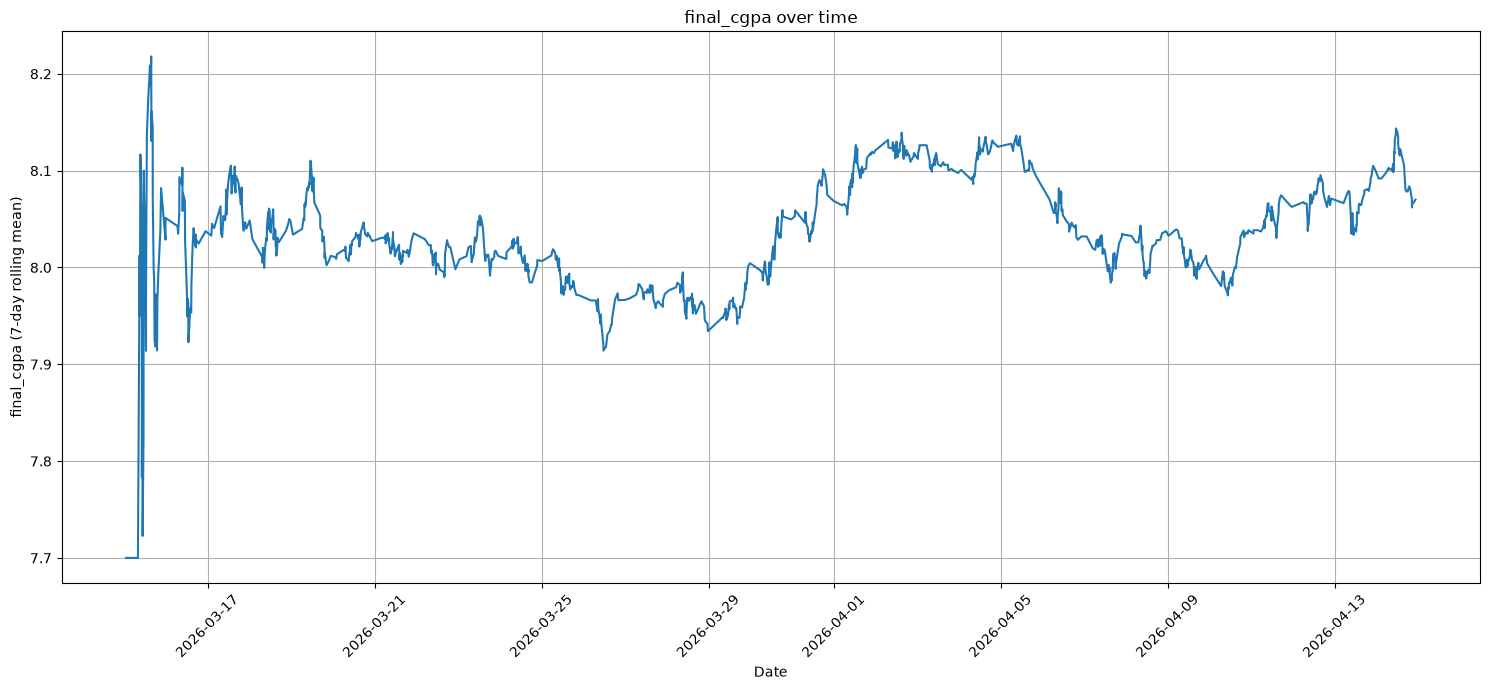

In [54]:
plt.figure(figsize=(15, 7))
plt.plot(rolling.index, rolling.values)
plt.grid()
plt.xlabel("Date")
plt.ylabel("final_cgpa (7-day rolling mean)")
plt.title("final_cgpa over time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

* There is no clear trend or drift; the mean stays near 8.0, consistent with the 0.02 correlation of submission_day with the target.

**Question:** Is the file in chronological order? Is there a trend or drift in `final_cgpa`?

**Answer:** No, it must be sorted by timestamp. There is no clear trend or drift (the mean stays near 8.0).

## Risk Summary (Part A)

| # | Risk | Problem it may cause |
|---|---|---|
| 1 | **Missing values** (511 cells, 35.6% of rows) | Dropping rows loses over a third of the data. Computing the median on all data leaks test information into training (**preprocessing leakage**). |
| 2 | **`performance_risk_level`** | It is derived from academic performance, so it is closely related to the target. Using it gives a falsely high R² (**target leakage**). |
| 3 | **Rare `cohort_code` categories** (12 of 42 categories have fewer than 10 students) | The model may memorize small groups instead of learning a general rule (**overfitting**). |
| 4 | **File not in chronological order** (597 backward jumps) | A random split mixes past and future, making the test score overly optimistic. We need to sort the data before the chronological split. |

# Part B : Impact of Data Leakage and Evaluation Strategy

## B.0 - Preparation


- Remove **student_id** and **performance_risk_level** (not features).
- Keep the 11 features + **submission_day**.
- **cohort_code** is set aside until D.1.
- Missing values are not fixed here: the Pipeline will impute them with the median.

In [55]:
features = ["study_hours", "sleep_hours_nb", "attendance_rate",
            "study_consistency_rate", "tasks_on_time_rate",
            "assignments_on_time_rate", "revision_frequency_rate",
            "career_goal_clarity_rate", "daily_productivity",
            "stress_level", "age", "submission_day"]

X = df_new[features]
y = df_new["final_cgpa"]

In [56]:
print(X.shape, y.shape)

(1200, 12) (1200,)


**Done**

## B.1 - Compare splitting strategies

In [57]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [58]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def make_tree():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(random_state=42))
    ])

### Random split

In [59]:
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, y, test_size=0.2, random_state=42)

tree_r = make_tree().fit(X_tr_r, y_tr_r)
base_r = DummyRegressor().fit(X_tr_r, y_tr_r)

### Chronological split

In [60]:
n_train = int(len(X) * 0.8)

X_tr, X_te = X.iloc[:n_train], X.iloc[n_train:]
y_tr, y_te = y.iloc[:n_train], y.iloc[n_train:]

tree_c = make_tree().fit(X_tr, y_tr)
base_c = DummyRegressor().fit(X_tr, y_tr)

### Results

In [61]:
results_b1 = pd.DataFrame({
    "Strategy": ["Random split", "Chronological split"],
    "Train RMSE": [rmse(y_tr_r, tree_r.predict(X_tr_r)), rmse(y_tr, tree_c.predict(X_tr))],
    "Test RMSE": [rmse(y_te_r, tree_r.predict(X_te_r)), rmse(y_te, tree_c.predict(X_te))],
    "Baseline Test RMSE": [rmse(y_te_r, base_r.predict(X_te_r)), rmse(y_te, base_c.predict(X_te))]
}).round(3)

print(results_b1)

              Strategy  Train RMSE  Test RMSE  Baseline Test RMSE
0         Random split         0.0      1.582               1.338
1  Chronological split         0.0      1.899               1.236


**Question:** Report training and testing RMSE for both strategies (and the baseline RMSE), and explain the difference.

**Answer:** 
* The tree has train RMSE = 0 (it memorizes the training data), but its test RMSE is higher than the baseline in both splits, so it is overfitting.
* The chronological split gives a worse test RMSE (1.95 vs 1.59) because it tests on future data, with no mixing of past and future, so it is the more honest estimate. 
* The random split is more optimistic.

## B.2 - Investigate duplicate leakage

### Build the augmented dataset

In [62]:
dups = df_new.sample(frac=0.15, random_state=42).copy()

rng = np.random.default_rng(42)
t_min, t_max = df_new["timestamp"].min(), df_new["timestamp"].max()
dups["timestamp"] = t_min + (t_max - t_min) * rng.random(len(dups))

aug = pd.concat([df_new, dups]).sort_values("timestamp").reset_index(drop=True)
aug["submission_day"] = (aug["timestamp"] - t_min).dt.days

In [63]:
print(len(df_new), len(aug))

1200 1380


In [64]:
def chrono_split(d):
    n = int(len(d) * 0.8)
    return d.iloc[:n], d.iloc[n:]

def eval_tree(train, test):
    model = make_tree().fit(train[features], train["final_cgpa"])
    return (rmse(train["final_cgpa"], model.predict(train[features])),
            rmse(test["final_cgpa"], model.predict(test[features])))

### (a) Split before removing duplicates

In [65]:
tr_a, te_a = chrono_split(aug)
train_rmse_a, test_rmse_a = eval_tree(tr_a, te_a)

print("test rows whose twin is in train :", te_a["student_id"].isin(tr_a["student_id"]).sum(), "of", len(te_a))
print(round(train_rmse_a, 3), round(test_rmse_a, 3))

test rows whose twin is in train : 50 of 276
0.0 1.569


### (b) Remove duplicates before splitting

In [66]:
cols = [c for c in aug.columns if c not in ("timestamp", "submission_day")]
aug_clean = aug.drop_duplicates(subset=cols, keep="first").reset_index(drop=True)
print(len(aug), len(aug_clean))

tr_b, te_b = chrono_split(aug_clean)
train_rmse_b, test_rmse_b = eval_tree(tr_b, te_b)

print("test rows whose twin is in train :", te_b["student_id"].isin(tr_b["student_id"]).sum(), "of", len(te_b))
print(round(train_rmse_b, 3), round(test_rmse_b, 3))

1380 1200
test rows whose twin is in train : 0 of 240
0.0 1.692


### Results

In [67]:
results_b2 = pd.DataFrame({
    "Strategy": ["Split before removing duplicates", "Remove duplicates before split"],
    "Train RMSE": [train_rmse_a, train_rmse_b],
    "Test RMSE": [test_rmse_a, test_rmse_b]
}).round(3)

print(results_b2)

                           Strategy  Train RMSE  Test RMSE
0  Split before removing duplicates         0.0      1.569
1    Remove duplicates before split         0.0      1.692


**Question:** Explain how a duplicated row can end up in both the training and the test set, and what this does to the test score.

**Answer:** 
* A student who submits twice creates two rows with the same answers but different timestamps.
* After sorting by time, one copy can fall in the first 80% (train) and the other in the last 20% (test). 
* The model has already seen the answer, so the test score looks better than it really is.
* The fix is to remove duplicates before splitting.

## B.3 - Investigate preprocessing leakage

- KNN works with distances, so scaling matters (a decision tree would show no difference).
- We compare fitting the scaler (and the median imputer) on **all data** vs on **train only**.

In [68]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

### (a) Leak : fit on the entire dataset

In [69]:
prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
X_all = prep.fit_transform(X)   # fitted on ALL rows (train + test)

knn_leak = KNeighborsRegressor(n_neighbors=10).fit(X_all[:n_train], y_tr)
train_leak = rmse(y_tr, knn_leak.predict(X_all[:n_train]))
test_leak = rmse(y_te, knn_leak.predict(X_all[n_train:]))

### (b) No leak : fit on train only (Pipeline)

In [70]:
knn_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", KNeighborsRegressor(n_neighbors=10))
]).fit(X_tr, y_tr)

train_ok = rmse(y_tr, knn_pipe.predict(X_tr))
test_ok = rmse(y_te, knn_pipe.predict(X_te))

### Results

In [71]:
results_b3 = pd.DataFrame({
    "Strategy": ["Scaler on all data (leak)", "Scaler on train only (Pipeline)"],
    "Train RMSE": [train_leak, train_ok],
    "Test RMSE": [test_leak, test_ok]
}).round(4)

print(results_b3)

                          Strategy  Train RMSE  Test RMSE
0        Scaler on all data (leak)      1.0681     1.1496
1  Scaler on train only (Pipeline)      1.0655     1.1454


**Question:** Compare testing RMSE and explain why preprocessing statistics must be learned from training data only.

**Answer:** 
* Test RMSE is almost the same: **1.150** (scaler on all data) vs **1.145** (scaler on train only). The gap is tiny.
* With the leak, the mean / std (and the median for missing values) are computed with the test rows inside, so the test set influences the training pipeline. The test is no longer "unseen".
* The gap is small here because we have 960 train rows vs 240 test rows, and the features are small ordinal ranges with no extreme outliers, so the statistics barely move.
* The principle still matters: with a small dataset, outliers or drift in time, the leaked statistics can change the score. In real life we never have the future data when we scale, so the Pipeline (fit on train only, only `transform` on test) is the only honest way.
* KNN (test 1.145) is already much better than the full tree (1.95) and than the baseline (1.236).

## Summary table (Part B)

In [72]:
summary_b = pd.DataFrame({
    "Strategy": ["B.1 Random split", "B.1 Chronological split",
                 "B.2 Split before removing duplicates", "B.2 Remove duplicates before split",
                 "B.3 Scaler on all data", "B.3 Scaler on train only"],
    "Train RMSE": list(results_b1["Train RMSE"]) + list(results_b2["Train RMSE"]) + [train_leak, train_ok],
    "Test RMSE": list(results_b1["Test RMSE"]) + list(results_b2["Test RMSE"]) + [test_leak, test_ok]
}).round(3)

print(summary_b)

                               Strategy  Train RMSE  Test RMSE
0                      B.1 Random split       0.000      1.582
1               B.1 Chronological split       0.000      1.899
2  B.2 Split before removing duplicates       0.000      1.569
3    B.2 Remove duplicates before split       0.000      1.692
4                B.3 Scaler on all data       1.068      1.150
5              B.3 Scaler on train only       1.066      1.145


**Short explanation :**
* **B.1** : the tree memorizes the train (RMSE 0) and is worse than the baseline on test in both splits. Chronological split is worse (1.95 vs 1.59) because it predicts the future from the past: it is the honest one.
* **B.2** : with duplicates left in, 50 of the 276 test rows have a twin in train, and the test RMSE looks better (1.53 vs 1.59). After removing duplicates, no twin is left (0 of 240). The tree has memorized the twins, so the leak gives an optimistic score.
* **B.3** : a leaked scaler changes the result only a little (1.150 vs 1.145), but it is still wrong in principle.

# Part C : Understanding and Diagnosing Overfitting

- We use the same chronological train / test sets of Part B (`X_tr`, `X_te`, `y_tr`, `y_te`).

## C.1 - Effect of model complexity

In [73]:
depths = [1, 2, 3, 5, 10, 20, None]
rows = []

for d in depths:
    m = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeRegressor(max_depth=d, random_state=42))
    ]).fit(X_tr, y_tr)
    tr, te = rmse(y_tr, m.predict(X_tr)), rmse(y_te, m.predict(X_te))
    rows.append({"max_depth": str(d), "Train RMSE": tr, "Test RMSE": te, "Gap": te - tr})

res_c1 = pd.DataFrame(rows).round(3)
base_test = rmse(y_te, base_c.predict(X_te))
print(res_c1)
print("baseline test RMSE :", round(base_test, 3))

  max_depth  Train RMSE  Test RMSE    Gap
0         1       1.179      1.159 -0.020
1         2       1.139      1.127 -0.013
2         3       1.102      1.068 -0.034
3         5       1.010      1.290  0.280
4        10       0.531      1.913  1.382
5        20       0.000      1.899  1.899
6      None       0.000      1.899  1.899
baseline test RMSE : 1.236


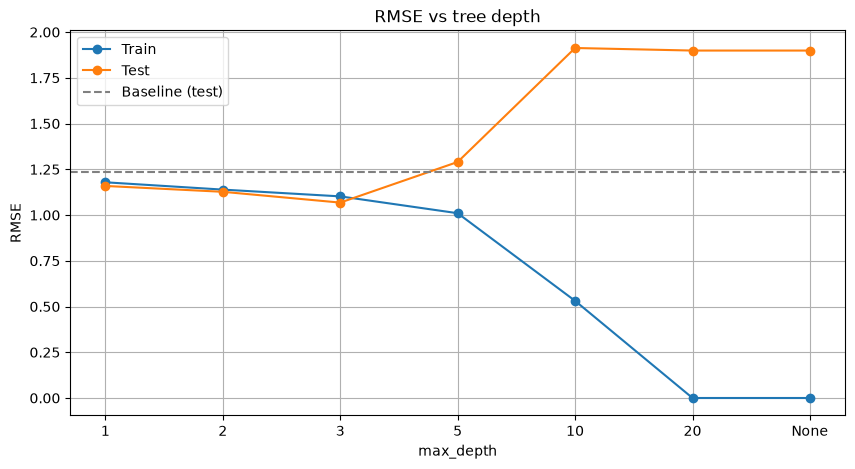

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(res_c1["max_depth"], res_c1["Train RMSE"], marker="o", label="Train")
plt.plot(res_c1["max_depth"], res_c1["Test RMSE"], marker="o", label="Test")
plt.axhline(base_test, color="gray", linestyle="--", label="Baseline (test)")
plt.xlabel("max_depth")
plt.ylabel("RMSE")
plt.title("RMSE vs tree depth")
plt.legend()
plt.grid()
plt.show()

**Question:** At which depth does the model start to overfit?

**Answer:** 
* Depth 1 to 3: train and test RMSE are close and the gap is about 0 (even negative: the test period is a bit "easier", its baseline RMSE is 1.236 vs 1.269 on train). Depth 3 is the best (test 1.068).
* **Depth 5 is where overfitting starts**: gap = 0.28 and the test RMSE (1.29) goes above the baseline (1.236).
* Depth 10: train 0.53, test 1.88 (gap 1.34). Depth 20 and None: train 0, test 1.95 (gap 1.95). The tree memorizes the noise, and a worse-than-baseline model is useless.
* Note: here the test errors are only for diagnosis. In Part D the depth is chosen with TimeSeriesSplit.

## C.2 - Effect of feature complexity

### Build effort_index

- Mean of the 6 scaled columns (each one divided by its max), ignoring missing answers in the row.
- The divisors are fixed, so nothing is learned from the data (no leakage).

In [75]:
df_new["effort_index"] = pd.concat([
    df_new["study_hours"] / 2.5,
    df_new["attendance_rate"] / 100,
    df_new["study_consistency_rate"] / 2,
    df_new["tasks_on_time_rate"] / 3,
    df_new["assignments_on_time_rate"] / 3,
    df_new["revision_frequency_rate"] / 3
], axis=1).mean(axis=1)   # mean() skips NaN

In [76]:
print(df_new["effort_index"].describe().round(3))
print("missing :", df_new["effort_index"].isna().sum())
print("corr with final_cgpa :", round(df_new["effort_index"].corr(df_new["final_cgpa"]), 3))
print("distinct values :", df_new["effort_index"].nunique())

count    1200.000
mean        0.538
std         0.150
min         0.156
25%         0.431
50%         0.534
75%         0.645
max         0.987
Name: effort_index, dtype: float64
missing : 0
corr with final_cgpa : 0.377
distinct values : 334


- `effort_index` has no missing values and 334 distinct values (instead of 3 for `study_hours`).
- Its correlation with the target (0.38) is higher than any single feature (attendance_rate was 0.36): combining 6 weak signals gives a better one.

### Polynomial degrees with TimeSeriesSplit

In [77]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

X_e_tr = df_new[["effort_index"]].iloc[:n_train]
X_e_te = df_new[["effort_index"]].iloc[n_train:]
tscv = TimeSeriesSplit(n_splits=5)

def poly_pipe(degree, model):
    return Pipeline([
        ("poly", PolynomialFeatures(degree, include_bias=False)),
        ("scaler", StandardScaler()),
        ("model", model)
    ])

def cv_rmse(model, X_, y_):
    s = -cross_val_score(model, X_, y_, cv=tscv, scoring="neg_root_mean_squared_error")
    return s.mean()

In [78]:
degrees = [1, 2, 3, 5, 9, 15]
cv_poly = [cv_rmse(poly_pipe(d, LinearRegression()), X_e_tr, y_tr) for d in degrees]
cv_base = cv_rmse(DummyRegressor(), X_e_tr, y_tr)

res_c2 = pd.DataFrame({"degree": degrees, "CV RMSE": cv_poly}).round(4)
print(res_c2)
print("baseline CV RMSE :", round(cv_base, 4))

   degree  CV RMSE
0       1   1.1774
1       2   1.1776
2       3   1.1789
3       5   1.1854
4       9   1.1883
5      15   1.2941
baseline CV RMSE : 1.268


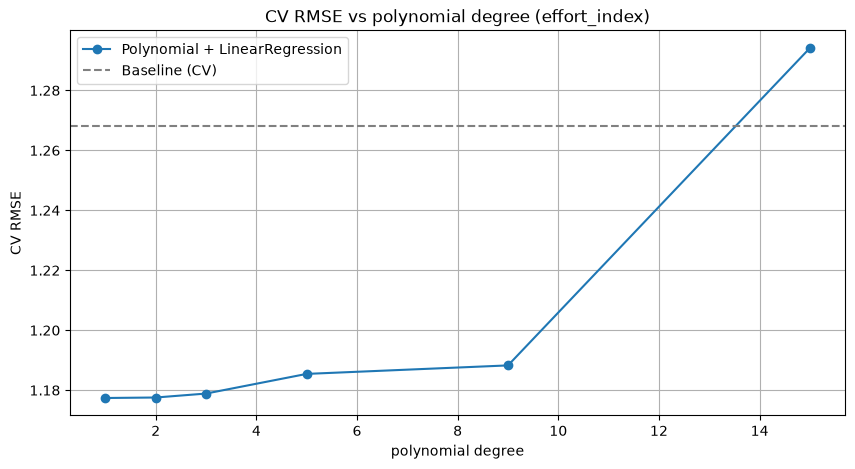

In [79]:
plt.figure(figsize=(10, 5))
plt.plot(degrees, cv_poly, marker="o", label="Polynomial + LinearRegression")
plt.axhline(cv_base, color="gray", linestyle="--", label="Baseline (CV)")
plt.xlabel("polynomial degree")
plt.ylabel("CV RMSE")
plt.title("CV RMSE vs polynomial degree (effort_index)")
plt.legend()
plt.grid()
plt.show()

**Question:** Interpret the plot, compare the size of the effect with C.1 and explain why.

**Answer:** 
* CV RMSE goes from **1.177** (degree 1) to **1.188** (degree 15). It increases slowly, so higher degrees are slightly worse and degree 1 (a straight line) is the best. All degrees stay better than the baseline (1.268).
* The effect is **tiny (about 0.01)** compared with C.1, where the test RMSE moved from 1.07 to 1.95.
* Why: this model has only **one** input and at most 15 coefficients, and a polynomial is a smooth curve that cannot jump around to fit single points. A deep tree can create one leaf per student (around 960 leaves), so it can memorize everything. Also `StandardScaler` keeps the high powers numerically stable, and the relationship between effort and CGPA is almost linear.
* So overfitting depends on the **real flexibility** of the model, not only on the number of parameters.

# Part D : Improving Model Generalization

- D.1 to D.3 : we compare options with **validation RMSE** (TimeSeriesSplit, 5 folds, train set only).
- The test set is used only in D.4.

## D.1 - High-cardinality categorical feature (cohort_code)

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
import warnings
warnings.filterwarnings("ignore")   # TargetEncoder(shuffle=...) FutureWarning

X_full = df_new[features + ["cohort_code"]]
X_full_tr = X_full.iloc[:n_train]

def tree_with(cohort_step):
    num = ("num", SimpleImputer(strategy="median"), features)
    steps = [num] if cohort_step is None else [num, ("cat", cohort_step, ["cohort_code"])]
    return Pipeline([
        ("prep", ColumnTransformer(steps)),
        ("model", DecisionTreeRegressor(max_depth=5, random_state=42))
    ])

In [81]:
options = {
    "Rare-category grouping": OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False),
    "Target encoding": TargetEncoder(cv=5, shuffle=False),
    "Feature removal": None
}

res_d1 = pd.Series({name: cv_rmse(tree_with(step), X_full_tr, y_tr) for name, step in options.items()})
print(res_d1.round(4))

Rare-category grouping    1.2211
Target encoding           1.2605
Feature removal           1.2423
dtype: float64


- Result : lower CV RMSE = better.

**Question:** Which treatment is best, and what does it tell about `cohort_code`?

**Answer:** 
* Rare-category grouping is the best (CV RMSE **1.221**), then Feature removal (1.242) and Target encoding (1.261, the worst).
* But the differences (0.02 to 0.04) are smaller than the variation between folds (std about 0.09), and for Linear Regression and Gradient Boosting `cohort_code` gives no gain (for LR, removal is best: 1.126 vs 1.139).
* The mean CGPA of the big cohorts is almost the same (about 8.0), so `cohort_code` is **weakly informative**. Target encoding is worse because small cohorts get noisy means.
* **Decision:** remove `cohort_code` (simpler model, no gain from keeping it).

## D.2 - Feature selection (submission_day)

In [82]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import GradientBoostingRegressor

def make_model(name):
    models = {
        "Linear Regression": LinearRegression(),
        "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=60, learning_rate=0.05, max_depth=3, random_state=42)
    }
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", models[name])])

no_day = [f for f in features if f != "submission_day"]

In [83]:
res_d2 = pd.DataFrame({
    name: {"with submission_day": cv_rmse(make_model(name), X_tr[features], y_tr),
           "without submission_day": cv_rmse(make_model(name), X_tr[no_day], y_tr)}
    for name in ["Linear Regression", "Decision Tree", "Gradient Boosting"]
}).T.round(4)

print(res_d2)

                   with submission_day  without submission_day
Linear Regression               1.1263                  1.1182
Decision Tree                   1.2423                  1.2015
Gradient Boosting               1.1291                  1.1275


### Optional : remove features with correlation close to 0

In [84]:
low_corr = ["sleep_hours_nb", "stress_level", "age"]          # from A.3.5
no_low = [f for f in no_day if f not in low_corr]

res_d2b = pd.DataFrame({
    name: {"no_day": cv_rmse(make_model(name), X_tr[no_day], y_tr),
           "no_day + no low-corr": cv_rmse(make_model(name), X_tr[no_low], y_tr)}
    for name in ["Linear Regression", "Decision Tree", "Gradient Boosting"]
}).T.round(4)

print(res_d2b)

                   no_day  no_day + no low-corr
Linear Regression  1.1182                1.1135
Decision Tree      1.2015                1.2001
Gradient Boosting  1.1275                1.1252


**Question:** Keep `submission_day` or not?

**Answer:** 
* Without `submission_day` the validation RMSE is lower or equal for all 3 models: LR 1.118 vs 1.126, Tree 1.202 vs 1.242, GB 1.1275 vs 1.1291.
* Reason: its correlation with the target is 0.02 (no information), and in a chronological split every test day is outside the training range, so the model can not use it correctly (a tree can only reuse the last train values, and LR extrapolates a line).
* **Decision: remove `submission_day`** for the rest of the session.
* Optional test: removing sleep_hours_nb, stress_level and age changes the RMSE by only 0.002 to 0.005 (LR 1.1182 to 1.1135). This is too small to be sure, so I keep them.

In [85]:
final_features = no_day   # decision of D.1 (cohort_code removed) and D.2 (submission_day removed)
print(final_features)

['study_hours', 'sleep_hours_nb', 'attendance_rate', 'study_consistency_rate', 'tasks_on_time_rate', 'assignments_on_time_rate', 'revision_frequency_rate', 'career_goal_clarity_rate', 'daily_productivity', 'stress_level', 'age']


## D.3 - Regularization (polynomial degree 5 of effort_index)

In [86]:
from sklearn.model_selection import GridSearchCV

alphas = [0.001, 0.01, 0.1, 1, 10, 100]

def search(model):
    gs = GridSearchCV(poly_pipe(5, model), {"model__alpha": alphas},
                      cv=tscv, scoring="neg_root_mean_squared_error")
    return gs.fit(X_e_tr, y_tr)

gs_ridge = search(Ridge())
gs_lasso = search(Lasso(max_iter=100000))

In [87]:
lr5 = poly_pipe(5, LinearRegression())
cv_lr5 = cv_rmse(lr5, X_e_tr, y_tr)

res_d3 = pd.DataFrame({
    "alpha": alphas,
    "Ridge CV RMSE": -gs_ridge.cv_results_["mean_test_score"],
    "Lasso CV RMSE": -gs_lasso.cv_results_["mean_test_score"]
}).round(4)

print(res_d3)
print("Linear Regression (no penalty) CV RMSE :", round(cv_lr5, 4))
print("best Ridge alpha :", gs_ridge.best_params_["model__alpha"])
print("best Lasso alpha :", gs_lasso.best_params_["model__alpha"])

     alpha  Ridge CV RMSE  Lasso CV RMSE
0    0.001         1.1808         1.1781
1    0.010         1.1800         1.1771
2    0.100         1.1790         1.1772
3    1.000         1.1784         1.2680
4   10.000         1.1782         1.2680
5  100.000         1.1805         1.2680
Linear Regression (no penalty) CV RMSE : 1.1854
best Ridge alpha : 10
best Lasso alpha : 0.01


### Coefficients

In [88]:
lr5.fit(X_e_tr, y_tr)
coefs = pd.DataFrame({
    "Linear": lr5["model"].coef_,
    "Ridge": gs_ridge.best_estimator_["model"].coef_,
    "Lasso": gs_lasso.best_estimator_["model"].coef_
}, index=[f"x^{i}" for i in range(1, 6)])

print(coefs.round(3))
print("Lasso coefficients exactly 0 :", (coefs["Lasso"] == 0).sum(), "of 5")

     Linear  Ridge  Lasso
x^1   8.831  0.394  0.471
x^2 -37.753  0.156  0.000
x^3  66.183  0.015  0.000
x^4 -52.515 -0.049 -0.000
x^5  15.761 -0.049 -0.000
Lasso coefficients exactly 0 : 4 of 5


**Question:** How do Ridge and Lasso change the coefficients? How many Lasso coefficients are exactly zero?

**Answer:** 
* Degree-5 Linear Regression has **huge coefficients** (8.8, -37.8, 66.2, -52.5, 15.8). They cancel each other because x, x², ..., x⁵ are strongly correlated. This is the typical sign of overfitting.
* **Ridge** (best alpha = 10, CV 1.1782) shrinks all of them below 0.5 but keeps all 5.
* **Lasso** (best alpha = 0.01, CV 1.1771) sets **4 of 5 coefficients exactly to 0** and keeps only x¹: it becomes a straight line. With alpha >= 1 all coefficients are 0 and the CV RMSE is 1.268 = the baseline.
* The CV gain compared with the no-penalty model (1.1854) is small (about 0.008), because with one feature the model was not overfitting much. The big change is in the coefficients, not in the RMSE.

## D.4 - Comparing the final models

- Same feature matrix for all models : `final_features` (the 11 Part B features : no `submission_day`, no `cohort_code`).
- Hyperparameters are chosen with TimeSeriesSplit on the train set only.

In [89]:
Xf_tr, Xf_te = X_tr[final_features], X_te[final_features]
imp = ("imputer", SimpleImputer(strategy="median"))
scorer = "neg_root_mean_squared_error"
final = {}   # name -> fitted model

### Linear Regression

In [90]:
final["Linear Regression"] = Pipeline([imp, ("scaler", StandardScaler()), ("model", LinearRegression())]).fit(Xf_tr, y_tr)

### Ridge / Lasso

In [91]:
def alpha_search(model):
    pipe = Pipeline([imp, ("scaler", StandardScaler()), ("model", model)])
    return GridSearchCV(pipe, {"model__alpha": alphas}, cv=tscv, scoring=scorer).fit(Xf_tr, y_tr)

gs_r, gs_l = alpha_search(Ridge()), alpha_search(Lasso(max_iter=100000))
print("Ridge : alpha =", gs_r.best_params_["model__alpha"], " CV RMSE =", round(-gs_r.best_score_, 4))
print("Lasso : alpha =", gs_l.best_params_["model__alpha"], " CV RMSE =", round(-gs_l.best_score_, 4))

best_rl = gs_r if gs_r.best_score_ >= gs_l.best_score_ else gs_l
final["Ridge / Lasso"] = best_rl.best_estimator_
print("chosen :", type(best_rl.best_estimator_["model"]).__name__)

Ridge : alpha = 100  CV RMSE = 1.1138
Lasso : alpha = 0.1  CV RMSE = 1.1073
chosen : Lasso


### Decision Tree

In [92]:
pipe_t = Pipeline([imp, ("model", DecisionTreeRegressor(random_state=42))])
gs_t = GridSearchCV(pipe_t, {"model__max_depth": [1, 2, 3, 5, 10, 20, None]}, cv=tscv, scoring=scorer).fit(Xf_tr, y_tr)

print("best max_depth :", gs_t.best_params_["model__max_depth"], " CV RMSE =", round(-gs_t.best_score_, 4))
final["Decision Tree"] = gs_t.best_estimator_

best max_depth : 3  CV RMSE = 1.1518


### Gradient Boosting with early stopping

- Last 15% of the train set (chronologically) = validation block.
- `staged_predict` gives the prediction after each tree, so we keep the number of trees with the lowest validation RMSE.

In [93]:
n_in = int(len(Xf_tr) * 0.85)
X_in, X_val = Xf_tr.iloc[:n_in], Xf_tr.iloc[n_in:]
y_in, y_val = y_tr.iloc[:n_in], y_tr.iloc[n_in:]

gb = Pipeline([imp, ("model", GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, random_state=42))]).fit(X_in, y_in)
val_curve = [rmse(y_val, p) for p in gb["model"].staged_predict(gb[:-1].transform(X_val))]

best_n = int(np.argmin(val_curve)) + 1
print("best number of trees :", best_n, " val RMSE =", round(min(val_curve), 4))

best number of trees : 48  val RMSE = 1.0705


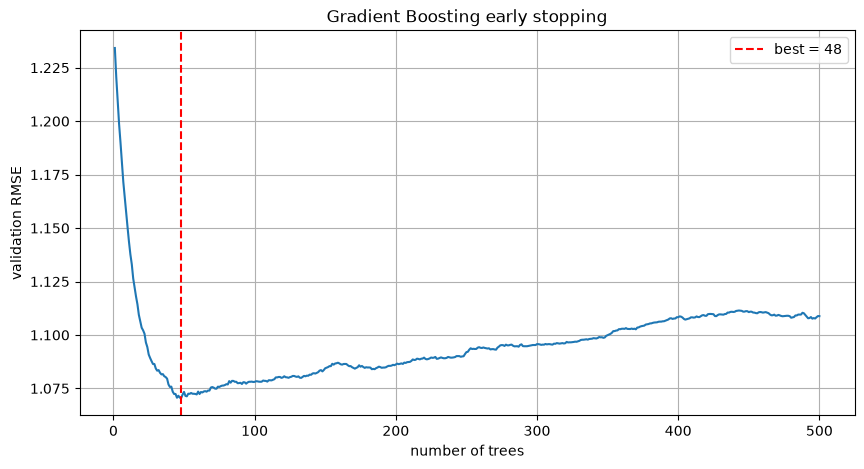

In [94]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, 501), val_curve)
plt.axvline(best_n, color="red", linestyle="--", label=f"best = {best_n}")
plt.xlabel("number of trees")
plt.ylabel("validation RMSE")
plt.title("Gradient Boosting early stopping")
plt.legend()
plt.grid()
plt.show()

In [95]:
final["Gradient Boosting"] = Pipeline([imp, ("model", GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.05, max_depth=3, random_state=42))]).fit(Xf_tr, y_tr)

### Final table (test set used once)

In [96]:
from sklearn.metrics import r2_score

base = DummyRegressor().fit(Xf_tr, y_tr)
rows = [{"Model": "Baseline (training mean)",
         "Train RMSE": rmse(y_tr, base.predict(Xf_tr)),
         "Test RMSE": rmse(y_te, base.predict(Xf_te)),
         "Test R²": r2_score(y_te, base.predict(Xf_te))}]

for name, m in final.items():
    rows.append({"Model": name,
                 "Train RMSE": rmse(y_tr, m.predict(Xf_tr)),
                 "Test RMSE": rmse(y_te, m.predict(Xf_te)),
                 "Test R²": r2_score(y_te, m.predict(Xf_te))})

res_d4 = pd.DataFrame(rows).set_index("Model")
res_d4["Gap"] = res_d4["Test RMSE"] - res_d4["Train RMSE"]
print(res_d4.round(3))

                          Train RMSE  Test RMSE  Test R²    Gap
Model                                                          
Baseline (training mean)       1.269      1.236   -0.003 -0.032
Linear Regression              1.090      1.058    0.266 -0.032
Ridge / Lasso                  1.106      1.072    0.246 -0.034
Decision Tree                  1.102      1.068    0.252 -0.034
Gradient Boosting              1.045      1.057    0.266  0.012


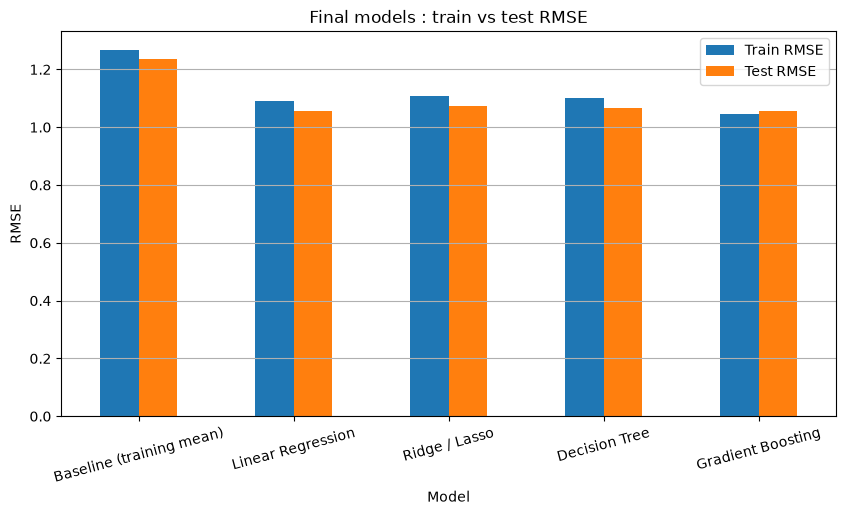

In [97]:
res_d4[["Train RMSE", "Test RMSE"]].plot(kind="bar", figsize=(10, 5), rot=15)
plt.ylabel("RMSE")
plt.title("Final models : train vs test RMSE")
plt.grid(axis="y")
plt.show()

**Reading the table :**
* GB (48 trees) and Linear Regression are tied: test RMSE 1.057 / 1.058, R² 0.266. The tree (depth 3) and Lasso (alpha 0.1) are a bit behind (1.068 / 1.072). All are better than the baseline (1.236, R² about 0).
* All the train/test gaps are tiny. They are negative for 3 models because the test period is easier (baseline RMSE 1.236 vs 1.269).

# Final Discussion

**1. Which model achieves the best generalization?**

Gradient Boosting (test RMSE 1.057, R² 0.266, 48 trees) and Linear Regression (1.058, R² 0.266) are tied. I would pick Linear Regression because it is simpler and gives the same score. Both are far better than the unpruned tree (1.95).

**2. Which model shows the largest generalization gap?**

In Part C, the unpruned decision tree: train 0 and test 1.95, gap = 1.95, worse than the baseline. Among the final models, Gradient Boosting has the biggest gap (+0.012), which is very small. The others have a negative gap because the test period is easier.

**3. Which techniques were most effective in reducing overfitting?**

Limiting the tree depth was the strongest (test RMSE 1.95 with None to 1.07 with depth 3). Then removing `submission_day`, early stopping for GB (48 trees instead of 500) and Lasso (it removes 4 of 5 polynomial terms). Regularization changed the coefficients a lot but the RMSE only a little (1.185 to 1.177). For honest evaluation: chronological split, removing duplicates before splitting and fitting preprocessing inside the Pipeline.

**4. Why should model selection rely on validation performance rather than training performance?**

Training error rewards memorization: the full tree has train RMSE 0 but test RMSE 1.95. A validation set (TimeSeriesSplit, always after the training part) imitates new data, so it tells us which model and which hyperparameters generalize.

**5. Why must the final test set remain untouched during model selection?**

If we use the test set to choose features or hyperparameters, we adapt the model to it and the final score becomes optimistic (selection bias). We would have no honest data left to estimate the real performance. That is why all choices in D.1 to D.3 used CV on the train set, and the test was used once in D.4.

**6. The best R² is modest. What does this tell you about the survey features, and why is a high score not always a sign of a good evaluation?**

R² = 0.27 means the survey explains only about a quarter of the CGPA variance. The answers are self-reported, in broad ranges, the target itself is only 4 bands, and the most important factors (exam results, previous grades, ability) are not in the survey. The strongest correlation was only 0.36. A high score is not always good: duplicates (1.53 vs 1.59), a random split (1.59 vs 1.95) or `performance_risk_level` (target leakage) would give a nicer number for the wrong reason. A modest R² on a clean evaluation is more honest than a high one on a leaky evaluation.